### Conditional Graph — Priya's Payout Currency Choice
Same payout as before, but now Priya can choose to receive it in INR or EUR. After the bonus is added, the graph checks `target_currency` and routes to whichever conversion node matches — the first real branching logic in this folder.

In [2]:
from typing import Literal, TypedDict


class PortfolioState(TypedDict):
    amount_usd: float
    total_usd: float
    target_currency: Literal["INR", "EUR"]
    total: float

In [3]:
BONUS_USD = 500  # fixed year-end bonus
def calc_total(state: PortfolioState) -> PortfolioState:
    state['total_usd'] = state['amount_usd'] + BONUS_USD # add Priya's 8% year-end performance bonus
    return state

def convert_to_inr(state: PortfolioState) -> PortfolioState:
    state['total'] = state['total_usd'] * 85  # approximate INR/USD rate
    return state

def convert_to_eur(state: PortfolioState) -> PortfolioState:
    state['total'] = state['total_usd'] * 0.9  # approximate EUR/USD rate
    return state

def choose_conversion(state: PortfolioState) -> str:
    # tells add_conditional_edges which branch to take, based on Priya's chosen currency
    return state["target_currency"]

In [4]:
from langgraph.graph import END, START, StateGraph

builder = StateGraph(PortfolioState)

builder.add_node("calc_total_node", calc_total)
builder.add_node("convert_to_inr_node", convert_to_inr)
builder.add_node("convert_to_eur_node", convert_to_eur)

builder.add_edge(START, "calc_total_node")
builder.add_conditional_edges(
    "calc_total_node",
    choose_conversion,
    {
        "INR": "convert_to_inr_node",
        "EUR": "convert_to_eur_node",
    }
)
builder.add_edge(["convert_to_inr_node", "convert_to_eur_node"], END)

graph = builder.compile()

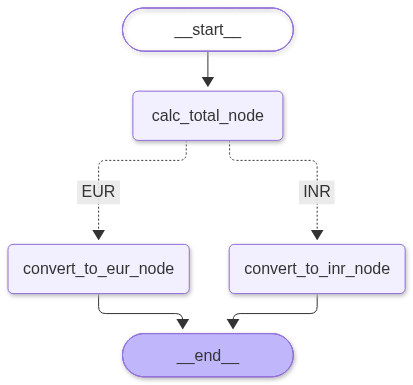

In [7]:
graph

In [9]:
graph.invoke({"amount_usd": 6200, "target_currency": "EUR"})

{'amount_usd': 6200,
 'total_usd': 6700,
 'target_currency': 'EUR',
 'total': 6030.0}

### 🤔 Before you move on
Every node here is a plain, deterministic Python function — no language model involved at all. What if a node's job is to actually think and respond in natural language instead of just doing fixed math? `3_chatbot.ipynb` puts an LLM inside a graph node for the first time.